In [1]:
# ── Repo-root bootstrap (added for folder reorg) ──────────────────────────────
# Make ../controllers and ../python importable and locate ../data, regardless of
# whether this notebook is launched from notebooks/ or the repository root.
import sys, os

ROOT = os.getcwd()
for _ in range(4):
    if os.path.isdir(os.path.join(ROOT, "controllers")):
        break
    ROOT = os.path.dirname(ROOT)
for _sub in ("controllers", "python"):
    _p = os.path.join(ROOT, _sub)
    if _p not in sys.path:
        sys.path.insert(0, _p)
DATA = os.path.join(ROOT, "data")

# Dubins car — reach-avoid MPC (TAC revision, Algorithm 1)

Changes w.r.t. the LCSS version (see `TAC_EXPERIMENT_UPDATE.md`):
terminal set $\{\Psi \ge \delta\}$, terminal cost $V_f = \omega(M_\Psi - \Psi)$ (no $Q_f$ term),
shifted candidate $\{u^*_{1|k},\dots,u^*_{N-1|k},u^c(\hat x^*_N)\}$ as warm start with the
cheaper-of rule, and the adaptive horizon $N \gets \max(N-1,1)$ when the candidate rollout touches $\mathcal X_T$.
The implementation lives in `python/ra_mpc_dubins.py`.

In [2]:
# ── Load computed certificate + controller ────────────────────────────────────
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import casadi as ca

from sop_bounded_control_dubins_car_result import (
    u_opt,
    certificate_opt,
    k1_opt,
)

u_opt = sp.Matrix(u_opt)
k1_opt = sp.Matrix(k1_opt)

# ── Symbolic variables ────────────────────────────────────────────────────────
x1, x2, th, v = sp.symbols("x1 x2 th v")
y1, y2 = sp.symbols("y1 y2")
state_vars = [x1, x2, th, v]

# ── Dubins-car dynamics ───────────────────────────────────────────────────────
f_sym = sp.Matrix([v * sp.cos(th), v * sp.sin(th), 0, 0])
g_sym = sp.Matrix([[0, 0], [0, 0], [1, 0], [0, 1]])
hx = sp.Matrix([x1, x2])

# ── Sets in output (y) space ─────────────────────────────────────────────────
h_raw = -(y1**4 + y2**4 - 16) * (y1**4 + y2**4 - 4)
target_set_y = (y2 - 0) ** 2 + (2 * (y1 + 1.7)) ** 2 - 0.4
alpha = 1e-3 * (-target_set_y + 300)
safe_set_y = alpha * h_raw

safe_set_x = safe_set_y.subs({y1: hx[0], y2: hx[1]})
target_set_x = target_set_y.subs({y1: hx[0], y2: hx[1]})

# ── Numpy callables ───────────────────────────────────────────────────────────
certificate_func = sp.lambdify(state_vars, certificate_opt, "numpy")
safe_set_y_func = sp.lambdify([y1, y2], safe_set_y, "numpy")
target_set_y_func = sp.lambdify([y1, y2], target_set_y, "numpy")
safe_set_x_func = sp.lambdify(state_vars, safe_set_x, "numpy")
target_set_x_func = sp.lambdify(state_vars, target_set_x, "numpy")
hx_func = sp.lambdify(state_vars, hx, "numpy")

print("Certificate symbols :", certificate_opt.free_symbols)
print("u_opt symbols       :", u_opt[0].free_symbols)

Certificate symbols : {x2, x1, th, v}
u_opt symbols       : {x2, x1, v, th}


In [3]:
# ── SymPy → CasADi converter (polynomials only; no trig in certificate) ───────
def sympy2casadi(expr, sym_map):
    """Recursively convert a SymPy polynomial expression to CasADi SX."""
    if isinstance(
        expr,
        (
            sp.Integer,
            sp.Float,
            sp.Rational,
            sp.core.numbers.NegativeOne,
            sp.core.numbers.Half,
            sp.core.numbers.One,
            sp.core.numbers.Zero,
            sp.core.numbers.Pi,
        ),
    ):
        return float(expr)
    elif isinstance(expr, sp.Symbol):
        return sym_map[expr]
    elif isinstance(expr, sp.Add):
        return sum(sympy2casadi(a, sym_map) for a in expr.args)
    elif isinstance(expr, sp.Mul):
        result = 1.0
        for a in expr.args:
            result = result * sympy2casadi(a, sym_map)
        return result
    elif isinstance(expr, sp.Pow):
        return sympy2casadi(expr.args[0], sym_map) ** sympy2casadi(
            expr.args[1], sym_map
        )
    elif isinstance(expr, sp.sin):
        return ca.sin(sympy2casadi(expr.args[0], sym_map))
    elif isinstance(expr, sp.cos):
        return ca.cos(sympy2casadi(expr.args[0], sym_map))
    elif isinstance(expr, sp.Number):
        return float(expr)
    else:
        raise ValueError(f"Unsupported sympy type: {type(expr)}  --  {expr}")


# ── CasADi SX symbols matching state_vars = [x1, x2, th, v] ─────────────────
ca_x1 = ca.SX.sym("x1")
ca_x2 = ca.SX.sym("x2")
ca_th = ca.SX.sym("th")
ca_v = ca.SX.sym("v")
sym_map = {x1: ca_x1, x2: ca_x2, th: ca_th, v: ca_v}

cert_ca_expr = sympy2casadi(certificate_opt, sym_map)
safe_ca_expr = sympy2casadi(safe_set_x, sym_map)

cert_ca_f = ca.Function("cert", [ca_x1, ca_x2, ca_th, ca_v], [cert_ca_expr])
safe_ca_f = ca.Function("safe", [ca_x1, ca_x2, ca_th, ca_v], [safe_ca_expr])


# Wrappers that accept a length-4 CasADi vector
def cert_vec(xv):
    return cert_ca_f(xv[0], xv[1], xv[2], xv[3])


def safe_vec(xv):
    return safe_ca_f(xv[0], xv[1], xv[2], xv[3])


# ── Sanity check ──────────────────────────────────────────────────────────────
test_x = np.array([0.5, 0.5, 3.5, 0.3])
v_sp = float(certificate_opt.subs(dict(zip(state_vars, test_x))))
v_ca = float(cert_ca_f(*test_x))
s_sp = float(safe_set_x.subs(dict(zip(state_vars, test_x))))
s_ca = float(safe_ca_f(*test_x))
print(f"Certificate:  sympy={v_sp:.6f}  casadi={v_ca:.6f}  diff={abs(v_sp-v_ca):.2e}")
print(f"Safe set:     sympy={s_sp:.6f}  casadi={s_ca:.6f}  diff={abs(s_sp-s_ca):.2e}")
assert abs(v_sp - v_ca) < 1e-4 and abs(s_sp - s_ca) < 1e-4, "Conversion mismatch!"
print("Conversions verified OK.")

Certificate:  sympy=-17.909830  casadi=-17.909830  diff=0.00e+00
Safe set:     sympy=-17.272972  casadi=-17.272972  diff=0.00e+00
Conversions verified OK.


In [4]:
# ── RA-MPC (TAC revision): shared implementation in python/ra_mpc_dubins.py ──
#   min   sum_k 5||h(x_k)-y*||^2 + 0.05||u_k||^2 + omega (M_Psi - Psi(x_N))
#   s.t.  x_{k+1} = RK4(x_k,u_k),  psi_safe(x_k) >= 0,  |u| <= 5,  Psi(x_N) >= delta
import ra_mpc_dubins as rm

dt_mpc = 0.05
N_hor = 25
u1_max, u2_max = rm.U_MAX
TARGET_POS = rm.TARGET_POS
DELTA = 0.1        # terminal margin delta (practical choice, see results notes)
OMEGA = 1000.0     # terminal-cost weight omega
ELL_LOWER = rm.ELL_LOWER  # stage-cost lower bound outside X_T (=0.5)

mpc = rm.DubinsRAMPC(dt=dt_mpc, N=N_hor, delta=DELTA, omega=OMEGA)
F_disc = mpc.F
print(f"RA-MPC ready: N={N_hor}, dt={dt_mpc}s, delta={DELTA}, omega={OMEGA}, "
      f"M_Psi={mpc.M_psi}, ell_lower={ELL_LOWER}")

RA-MPC ready: N=25, dt=0.05s, delta=0.1, omega=1000.0, M_Psi=11.63, ell_lower=0.5


In [5]:
# ── Sample (same seed/bounds as other notebooks) + MPC feasibility check ──────
N_samples = 1000
np.random.seed(42)

lower_bound = np.array([-2.0, -2.0, 2 * np.pi / 3, -1.0])
upper_bound = np.array([2.0, 2.0, 4 * np.pi / 3, 1.0])

x_samples = np.random.rand(4, N_samples) * (upper_bound - lower_bound).reshape(
    -1, 1
) + lower_bound.reshape(-1, 1)

safe_vals = np.atleast_1d(np.squeeze(safe_set_x_func(*x_samples)))
target_vals = np.atleast_1d(np.squeeze(target_set_x_func(*x_samples)))

# Candidates: inside safe set AND outside target set
candidate_mask = (safe_vals >= 0) & (target_vals > 0)
candidate_idx = np.where(candidate_mask)[0]
# only keep the first 300 candidates to speed up the MPC checks
candidate_idx = candidate_idx[:300]
print(f"Total samples : {N_samples}")
print(f"Candidates (safe & outside target): {len(candidate_idx)}")


# ── Closed-loop evaluation of Algorithm 1 (nominal RK4 model, <= 10 s) ────────
from joblib import Parallel, delayed

T_feas_ra = 10.0
print(f"Running Algorithm 1 from {len(candidate_idx)} candidates ...")
_logs = Parallel(n_jobs=-1, prefer="processes", verbose=0)(
    delayed(rm.run_one)(x_samples[:, i], dt_mpc, N_hor, DELTA, OMEGA, T_feas_ra)
    for i in candidate_idx
)
LOGS = dict(zip(candidate_idx, _logs))

mpc_feasible_idx = np.array([i for i in candidate_idx if LOGS[i]["status"] == "reached"])
mpc_infeasible_idx = np.array([i for i in candidate_idx if LOGS[i]["status"] != "reached"])
n_c = len(candidate_idx)
from collections import Counter
print(Counter(LOGS[i]["status"] for i in candidate_idx))
print(f"RA-MPC reached:     {len(mpc_feasible_idx):3d} / {n_c} ({100*len(mpc_feasible_idx)/n_c:.1f}%)")
print(f"RA-MPC not reached: {len(mpc_infeasible_idx):3d} / {n_c}")

Total samples : 1000
Candidates (safe & outside target): 300
Running Algorithm 1 from 300 candidates ...


Counter({'reached': 284, 'infeasible': 11, 'timeout': 5})
RA-MPC reached:     284 / 300 (94.7%)
RA-MPC not reached:  16 / 300


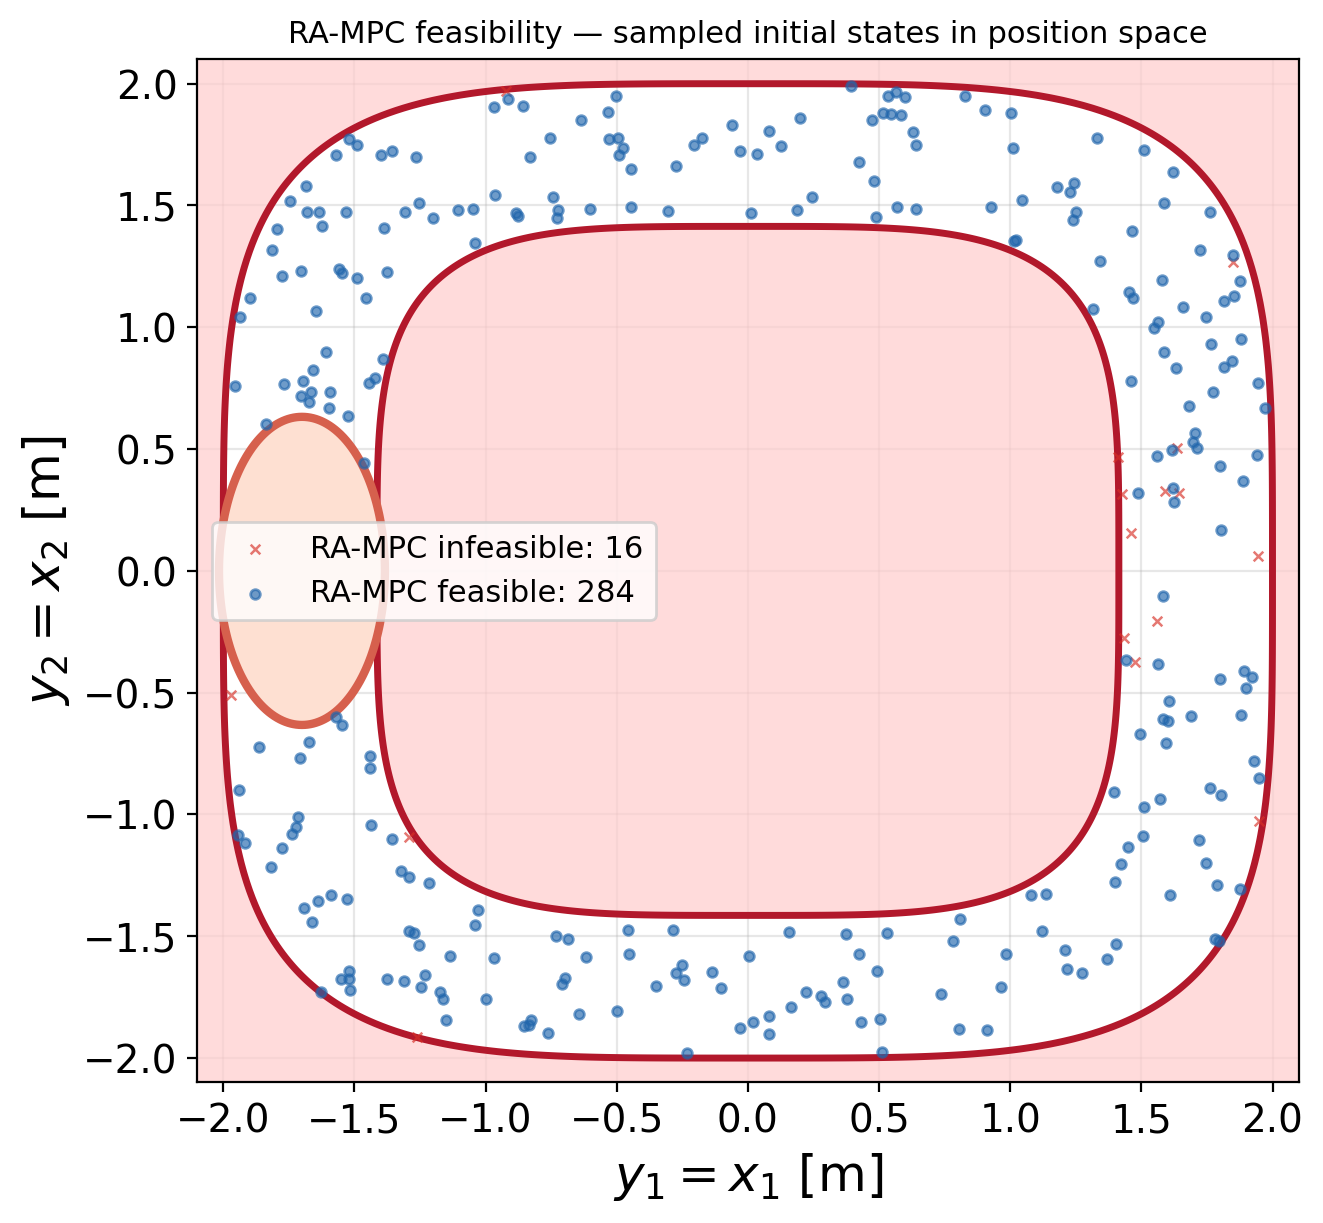

In [6]:
# ── Visualise RA-MPC feasible / infeasible initial states ─────────────────────
from functional import BetterColor

y_feasible = np.array(hx_func(*x_samples[:, mpc_feasible_idx])).reshape(2, -1)
y_infeasible = np.array(hx_func(*x_samples[:, mpc_infeasible_idx])).reshape(2, -1)

n_grid = 400
y1_g = np.linspace(-2.1, 2.1, n_grid)
y2_g = np.linspace(-2.1, 2.1, n_grid)
Y1, Y2 = np.meshgrid(y1_g, y2_g)
Z_safe = safe_set_y_func(Y1, Y2)
Z_target = target_set_y_func(Y1, Y2)

px_fig = 1 / plt.rcParams["figure.dpi"]
fig, ax = plt.subplots(figsize=(650 * px_fig, 600 * px_fig), layout="constrained")
fig.set_dpi(200)

ax.contourf(
    Y1, Y2, Z_safe, levels=[-np.inf, 0], colors=["#ffcccc"], alpha=0.7, zorder=2
)
ax.contour(Y1, Y2, Z_safe, levels=[0], colors=["#b2182b"], linewidths=2.5, zorder=3)
ax.contourf(
    Y1, Y2, Z_target, levels=[-np.inf, 0], colors=["#fee0d2"], alpha=1.0, zorder=4
)
ax.contour(Y1, Y2, Z_target, levels=[0], colors=["#d6604d"], linewidths=3, zorder=5)

ax.scatter(
    y_infeasible[0],
    y_infeasible[1],
    s=12,
    color="#d73027",
    alpha=0.65,
    marker="x",
    linewidths=0.9,
    label=f"RA-MPC infeasible: {len(mpc_infeasible_idx)}",
    zorder=9,
)
ax.scatter(
    y_feasible[0],
    y_feasible[1],
    s=12,
    color="#2166ac",
    alpha=0.65,
    marker="o",
    label=f"RA-MPC feasible: {len(mpc_feasible_idx)}",
    zorder=10,
)

fs = 22
ax.set_xlabel("$y_1 = x_1$ [m]", fontsize=fs - 4)
ax.set_ylabel("$y_2 = x_2$ [m]", fontsize=fs - 4)
ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_title(
    "RA-MPC feasibility — sampled initial states in position space", fontsize=11
)
plt.show()

In [7]:
# ── Closed-loop trajectories (taken from the Algorithm 1 logs above) ─────────
T_max = 10.0
T_min = 1.1
phi_tol = 0.05

N_sim_try = min(50, len(mpc_feasible_idx))
traj_t = [LOGS[i]["t"] for i in mpc_feasible_idx[:N_sim_try]]
traj_x = [LOGS[i]["x"] for i in mpc_feasible_idx[:N_sim_try]]
traj_y = [x[:, :2] for x in traj_x]
for k, (tt, tx) in enumerate(zip(traj_t, traj_x)):
    print(f"  [{k+1:2d}/{N_sim_try}] T={tt[-1]:.2f}s  "
          f"{'REACHED' if float(np.squeeze(target_set_x_func(*tx[-1]))) <= 0 else 'not reached'}")

  [ 1/50] T=1.60s  REACHED
  [ 2/50] T=1.35s  REACHED
  [ 3/50] T=0.60s  REACHED
  [ 4/50] T=0.45s  REACHED
  [ 5/50] T=1.50s  REACHED
  [ 6/50] T=0.65s  REACHED
  [ 7/50] T=1.55s  REACHED
  [ 8/50] T=0.85s  REACHED
  [ 9/50] T=0.80s  REACHED
  [10/50] T=1.30s  REACHED
  [11/50] T=0.80s  REACHED
  [12/50] T=0.40s  REACHED
  [13/50] T=0.75s  REACHED
  [14/50] T=1.05s  REACHED
  [15/50] T=1.20s  REACHED
  [16/50] T=0.55s  REACHED
  [17/50] T=0.65s  REACHED
  [18/50] T=1.35s  REACHED
  [19/50] T=0.60s  REACHED
  [20/50] T=1.70s  REACHED
  [21/50] T=0.60s  REACHED
  [22/50] T=1.60s  REACHED
  [23/50] T=0.20s  REACHED
  [24/50] T=0.70s  REACHED
  [25/50] T=1.20s  REACHED
  [26/50] T=1.20s  REACHED
  [27/50] T=1.55s  REACHED
  [28/50] T=1.20s  REACHED
  [29/50] T=1.45s  REACHED
  [30/50] T=0.50s  REACHED
  [31/50] T=1.05s  REACHED
  [32/50] T=1.10s  REACHED
  [33/50] T=1.60s  REACHED
  [34/50] T=0.70s  REACHED
  [35/50] T=1.20s  REACHED
  [36/50] T=1.45s  REACHED
  [37/50] T=1.25s  REACHED
 

Kept 1/50 trajectories  (removed 49: hit T_max or did not reach target)


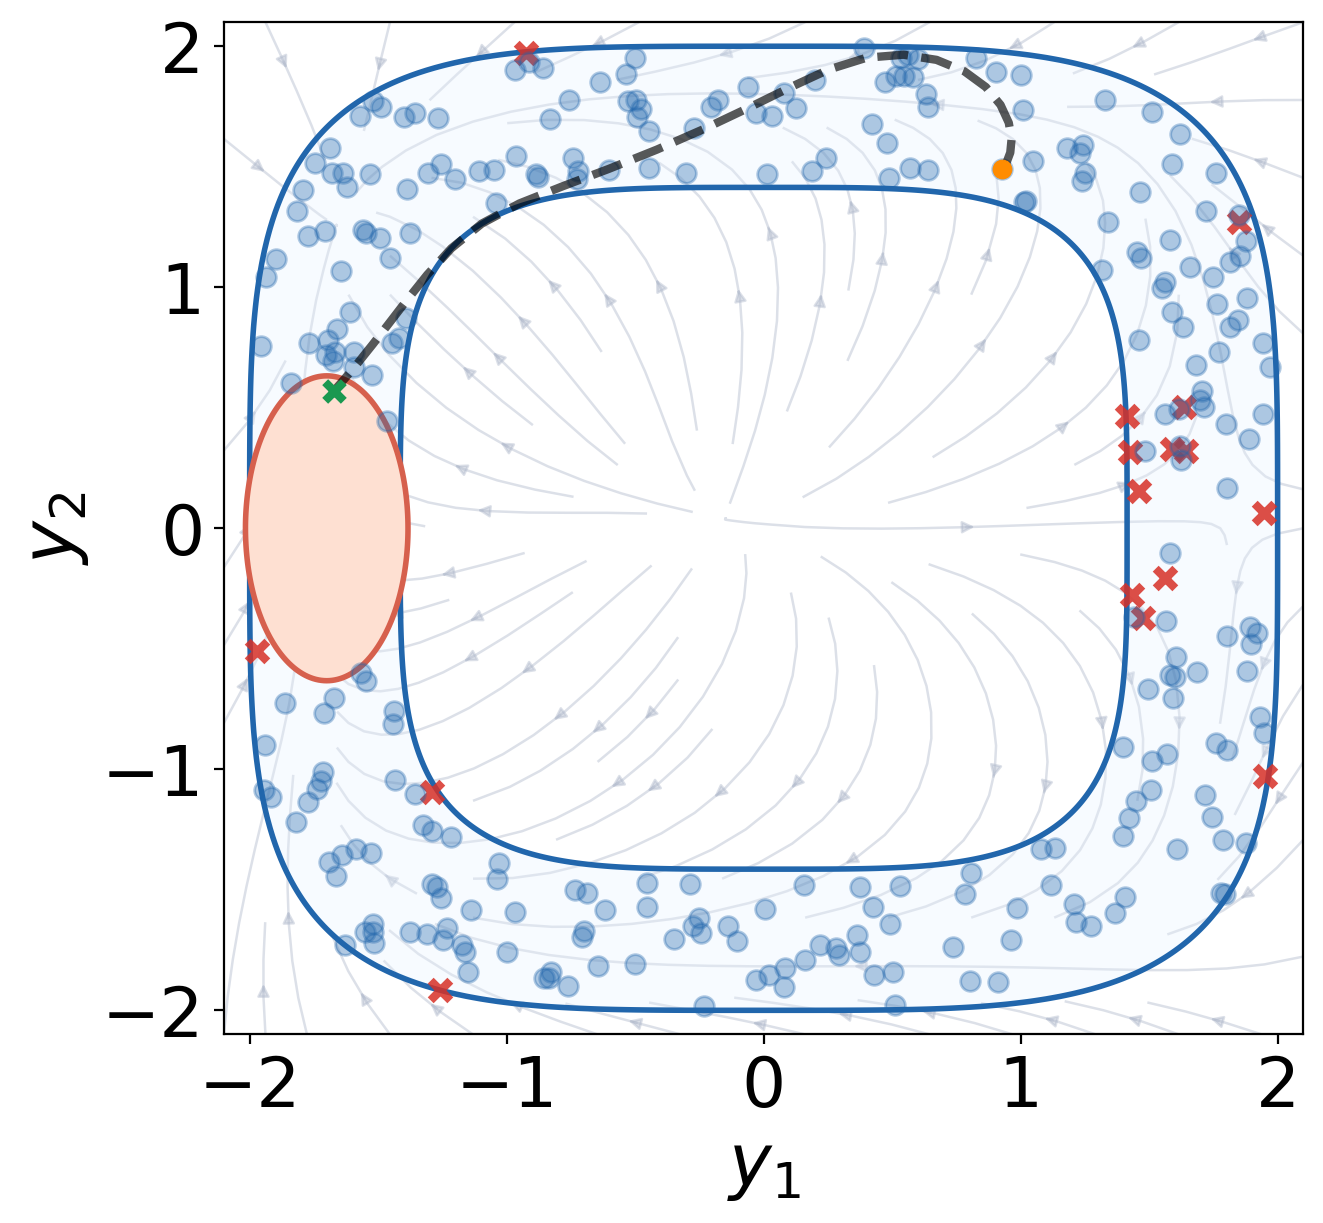

In [8]:
# ── Filter + visualise trajectories (same style as unconstrained notebook) ────
# Style mirrors example_dubins_car_unconstrained_reach_avoid.ipynb cell 8:
#   - fs=30 tick labels, fs-4 axis labels
#   - unsafe region: #ffcccc fill / #b2182b boundary
#   - target region: #fee0d2 fill / #d6604d boundary
#   - trajectory: black dashed lw=2
#   - start: BetterColor.orange3() circle
#   - end:   BetterColor.green0() x

filtered = [
    (tt, tx, ty)
    for tt, tx, ty in zip(traj_t, traj_x, traj_y)
    if tt[-1] < T_max - 1e-6
    and tt[-1] >= T_min
    and float(np.squeeze(target_set_x_func(*tx[-1]))) <= phi_tol
][1:2]

print(
    f"Kept {len(filtered)}/{len(traj_t)} trajectories  "
    f"(removed {len(traj_t)-len(filtered)}: hit T_max or did not reach target)"
)
traj_t_plot, traj_x_plot, traj_y_plot = zip(*filtered) if filtered else ([], [], [])

# ── Set contour grids ─────────────────────────────────────────────────────────
n_grid = 400
y1_g = np.linspace(-2.1, 2.1, n_grid)
y2_g = np.linspace(-2.1, 2.1, n_grid)
Y1, Y2 = np.meshgrid(y1_g, y2_g)
Z_safe_y = safe_set_y_func(Y1, Y2)
Z_target_y = target_set_y_func(Y1, Y2)

# ── k1 vector field ───────────────────────────────────────────────────────────
k1_func = sp.lambdify([y1, y2], list(k1_opt), "numpy")
n_vf = 30
y1_vf = np.linspace(-2.1, 2.1, n_vf)
y2_vf = np.linspace(-2.1, 2.1, n_vf)
VF_Y1, VF_Y2 = np.meshgrid(y1_vf, y2_vf)
k1_vals = np.array(k1_func(VF_Y1, VF_Y2)).squeeze()
U_k1, V_k1 = k1_vals[0], k1_vals[1]

px_fig = 1 / plt.rcParams["figure.dpi"]
fig, ax = plt.subplots(figsize=(650 * px_fig, 600 * px_fig), layout="constrained")
fig.set_dpi(200)

# k1 streamlines (background)
ax.streamplot(
    y1_vf,
    y2_vf,
    U_k1,
    V_k1,
    color=BetterColor.gray0(0.45),
    linewidth=0.9,
    density=0.9,
    arrowsize=0.9,
    zorder=1,
)

# Safe / unsafe region
ax.contourf(
    Y1, Y2, Z_safe_y, levels=[0, np.inf], colors=["#e6f2ff"], alpha=0.3, zorder=1
)
ax.contour(Y1, Y2, Z_safe_y, levels=[0], colors=["#2166ac"], linewidths=2, zorder=2)
# Target region
ax.contourf(
    Y1, Y2, Z_target_y, levels=[-np.inf, 0], colors=["#fee0d2"], alpha=1.0, zorder=3
)
ax.contour(Y1, Y2, Z_target_y, levels=[0], colors=["#d6604d"], linewidths=2, zorder=4)

# Feasible / infeasible scatter
ax.scatter(
    y_infeasible[0],
    y_infeasible[1],
    s=50,
    color="#d73027",
    alpha=0.85,
    marker="x",
    linewidths=3,
    label=f"RA-MPC infeasible: {len(mpc_infeasible_idx)}",
    zorder=8,
)
ax.scatter(
    y_feasible[0],
    y_feasible[1],
    s=50,
    color="#2166ac",
    alpha=0.35,
    marker="o",
    label=f"RA-MPC feasible: {len(mpc_feasible_idx)}",
    zorder=9,
)

# Trajectories
for ty in traj_y_plot:
    ax.plot(
        ty[:, 0], ty[:, 1], color="black", lw=3, alpha=0.65, linestyle="--", zorder=10
    )
    ax.scatter(
        ty[0, 0],
        ty[0, 1],
        s=45,
        c=[BetterColor.orange3()],
        marker="o",
        linewidths=0.4,
        zorder=20,
    )
    ax.scatter(
        ty[-1, 0],
        ty[-1, 1],
        s=45,
        c=[BetterColor.green0()],
        marker="x",
        linewidths=3.0,
        zorder=20,
    )

fs = 30
ax.set_xlabel("$y_1$", fontsize=fs - 4)
ax.set_ylabel("$y_2$", fontsize=fs - 4)
ax.xaxis.set_tick_params(labelsize=25)
ax.yaxis.set_tick_params(labelsize=25)
plt.show()

In [9]:
# ── Export filtered trajectory data for cross-method comparison ───────────────
if len(traj_t_plot) > 0:
    # Recover piecewise-constant MPC controls from state finite differences
    u1_list, u2_list = [], []
    for tt, tx in zip(traj_t_plot, traj_x_plot):
        dt_arr = np.diff(tt)
        u1_list.append(np.diff(tx[:, 2]) / dt_arr)  # dtheta/dt ≈ u1
        u2_list.append(np.diff(tx[:, 3]) / dt_arr)  # dv/dt     ≈ u2

    np.savez(
        os.path.join(DATA, "traj_controls_reach_avoid_mpc.npz"),
        traj_t=np.array(traj_t_plot, dtype=object),
        traj_x=np.array(traj_x_plot, dtype=object),
        traj_y=np.array(traj_y_plot, dtype=object),
        u1_traj=np.array(u1_list, dtype=object),
        u2_traj=np.array(u2_list, dtype=object),
        dt_mpc=np.array([dt_mpc]),
        u1_max=np.array([u1_max]),
        u2_max=np.array([u2_max]),
    )
    print(
        f"Saved {len(traj_t_plot)} trajectory/ies to traj_controls_reach_avoid_mpc.npz"
    )
    for i, (tt, u1, u2) in enumerate(zip(traj_t_plot, u1_list, u2_list)):
        print(
            f"  traj {i+1}: {len(tt)} states, {len(u1)} control steps, "
            f"u1 in [{u1.min():.2f}, {u1.max():.2f}], "
            f"u2 in [{u2.min():.2f}, {u2.max():.2f}]"
        )

Saved 1 trajectory/ies to traj_controls_reach_avoid_mpc.npz
  traj 1: 28 states, 27 control steps, u1 in [-0.69, 5.00], u2 in [-5.00, 5.00]


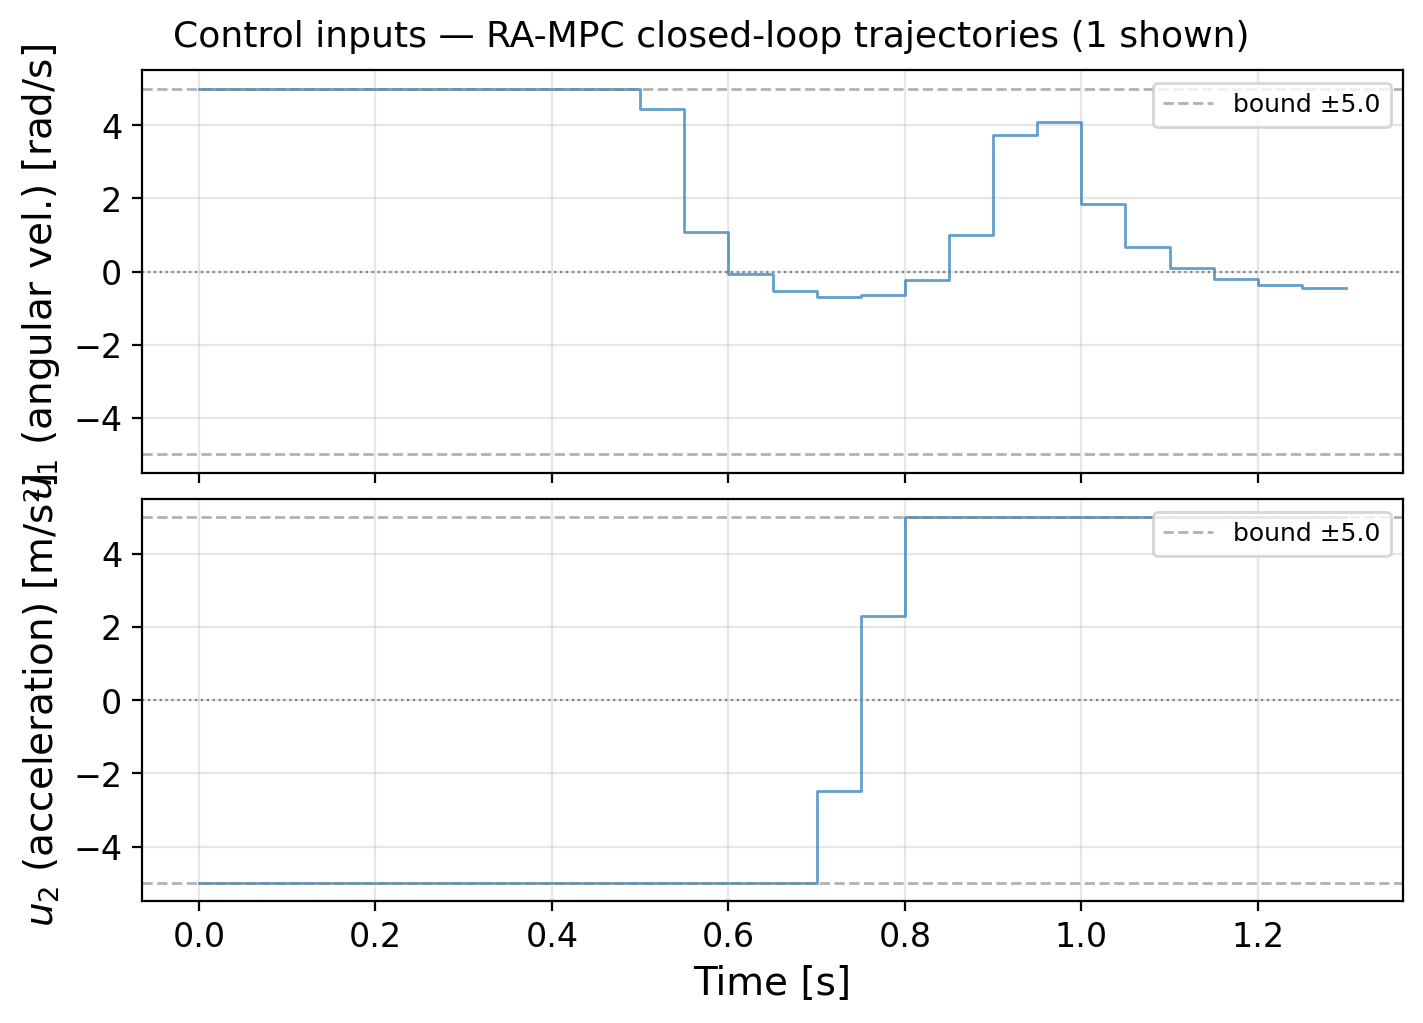

In [10]:
# ── Control inputs along the filtered trajectories ────────────────────────────
# RA-MPC holds u constant over each dt_mpc interval;
# recover u1 = dtheta/dt and u2 = dv/dt from the simulated states.

px_fig = 1 / plt.rcParams["figure.dpi"]
fig, axes = plt.subplots(
    2, 1, figsize=(700 * px_fig, 500 * px_fig), layout="constrained", sharex=True
)
fig.set_dpi(200)

for tt, tx in zip(traj_t_plot, traj_x_plot):
    if len(tt) < 2:
        continue
    dt_arr = np.diff(tt)
    u1_approx = np.diff(tx[:, 2]) / dt_arr  # dtheta/dt ≈ u1
    u2_approx = np.diff(tx[:, 3]) / dt_arr  # dv/dt     ≈ u2
    axes[0].step(tt[:-1], u1_approx, lw=1.0, alpha=0.7, where="post")
    axes[1].step(tt[:-1], u2_approx, lw=1.0, alpha=0.7, where="post")

for ax, lbl, bnd in zip(
    axes,
    ["$u_1$ (angular vel.) [rad/s]", "$u_2$ (acceleration) [m/s\u00b2]"],
    [u1_max, u2_max],
):
    ax.axhline(
        bnd, color="gray", lw=1.0, ls="--", alpha=0.6, label=f"bound \u00b1{bnd}"
    )
    ax.axhline(-bnd, color="gray", lw=1.0, ls="--", alpha=0.6)
    ax.axhline(0, color="gray", lw=0.8, ls=":")
    ax.set_ylabel(lbl, fontsize=14)
    ax.tick_params(labelsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, loc="upper right")

axes[1].set_xlabel("Time [s]", fontsize=14)
fig.suptitle(
    f"Control inputs — RA-MPC closed-loop trajectories ({len(traj_t_plot)} shown)",
    fontsize=13,
)
plt.show()

## Cost evolution and Corollary 1 (latest entry time)

Corollary 1: $J^*_{k+1} \le J^*_k - \underline{\ell}$ at every step, hence $\mathcal X_T$ is entered no later than
$t_{\text{bound}} = (\lfloor J^*_0/\underline{\ell}\rfloor + 1)\,T$.

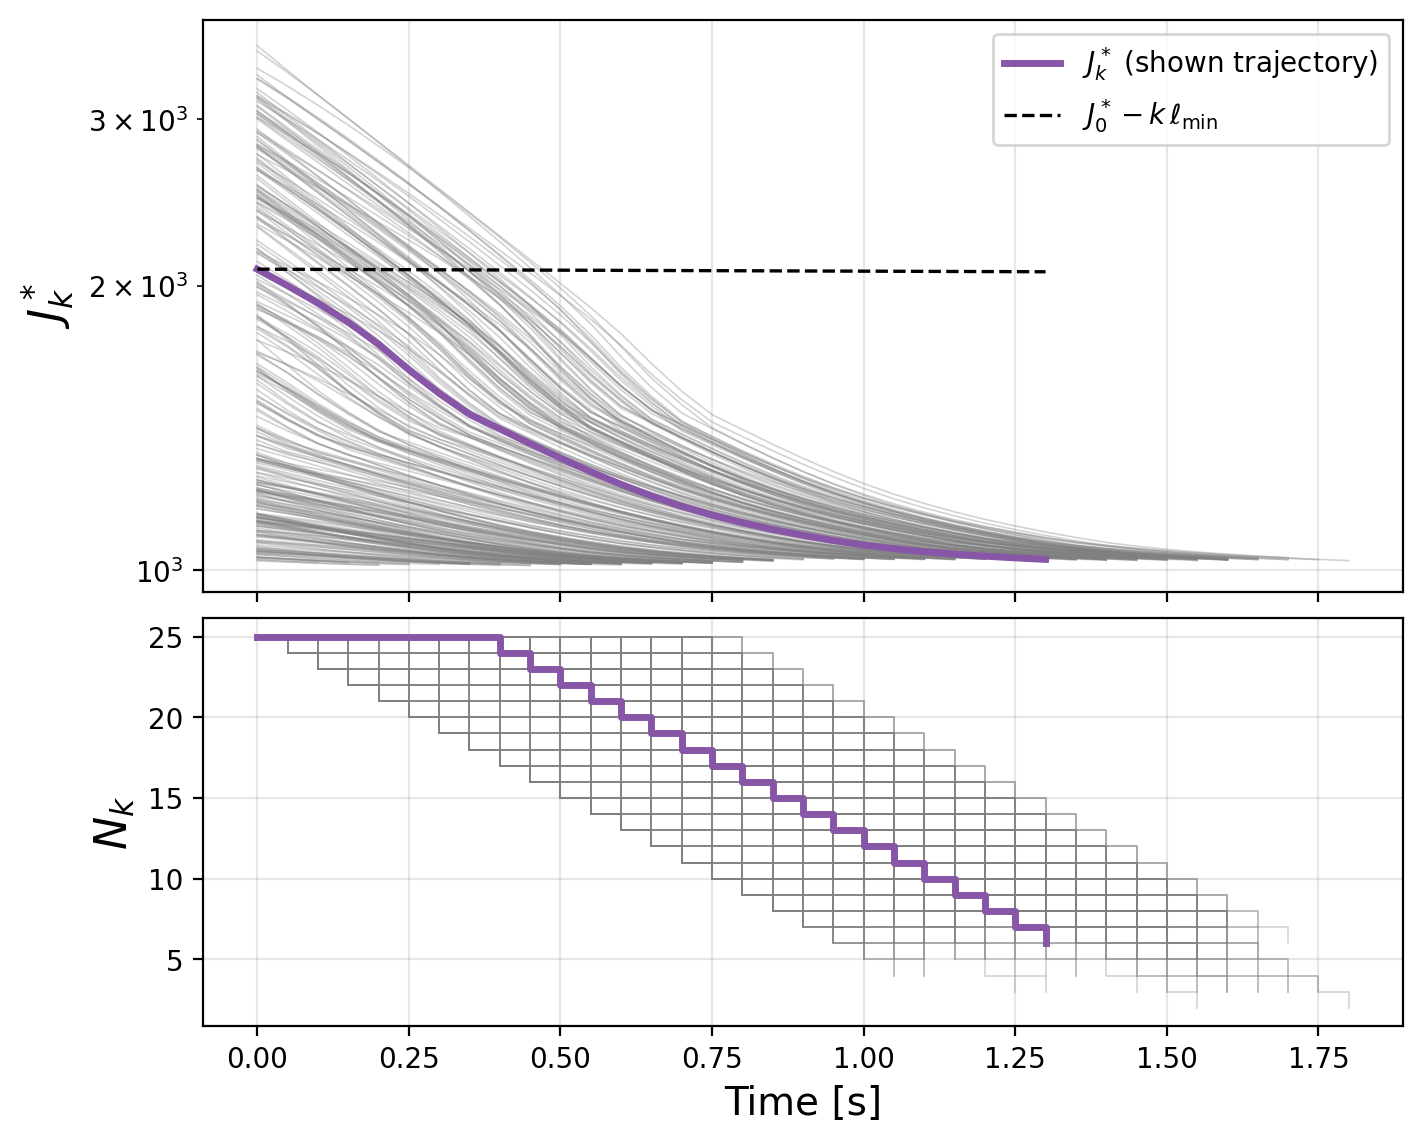

steps checked: 5900,  violations of J_(k+1) <= J_k - ell_lower: 0  (max excess -1.53)


In [11]:
# ── Cost J*_k and horizon N_k along the closed loop ───────────────────────────
reached = [i for i in candidate_idx if LOGS[i]["status"] == "reached"]
show = LOGS[traj_idx_show] if "traj_idx_show" in dir() else None
if show is None and len(traj_t_plot):
    for i in reached:
        if np.array_equal(LOGS[i]["x"], traj_x_plot[0]):
            show = LOGS[i]; break

fig, (axJ, axN) = plt.subplots(2, 1, figsize=(700 * px_fig, 560 * px_fig), sharex=True,
                               layout="constrained", gridspec_kw={"height_ratios": [1.4, 1.0]})
fig.set_dpi(200)
for i in reached:
    L = LOGS[i]
    axJ.semilogy(L["t"][:-1], L["J"], color="gray", lw=0.6, alpha=0.35)
    axN.step(L["t"][:-1], L["N"], where="post", color="gray", lw=0.6, alpha=0.35)
if show is not None:
    tt = show["t"][:-1]
    axJ.semilogy(tt, show["J"], color="#8856a7", lw=2.5, label=r"$J^*_k$ (shown trajectory)")
    axJ.semilogy(tt, np.maximum(show["J"][0] - ELL_LOWER * np.arange(len(tt)), 1e-1), color="black",
                 ls="--", lw=1.2, label=r"$J^*_0 - k\,\ell_{\min}$")
    axN.step(tt, show["N"], where="post", color="#8856a7", lw=2.5)
axJ.set_ylabel(r"$J^*_k$", fontsize=16); axJ.grid(True, alpha=0.3); axJ.legend(fontsize=10)
axN.set_ylabel(r"$N_k$", fontsize=16); axN.set_xlabel("Time [s]", fontsize=14); axN.grid(True, alpha=0.3)
fig.savefig(os.path.join(ROOT, "figures", "tac_dubins_cost.png"), dpi=200)
plt.show()

# per-step decrease check  J_{k+1} - J_k + ell_lower <= 0
dec = np.concatenate([np.diff(LOGS[i]["J"]) + ELL_LOWER for i in reached if len(LOGS[i]["J"]) > 1])
print(f"steps checked: {dec.size},  violations of J_(k+1) <= J_k - ell_lower: {(dec > 1e-6).sum()}"
      f"  (max excess {dec.max():.3g})")

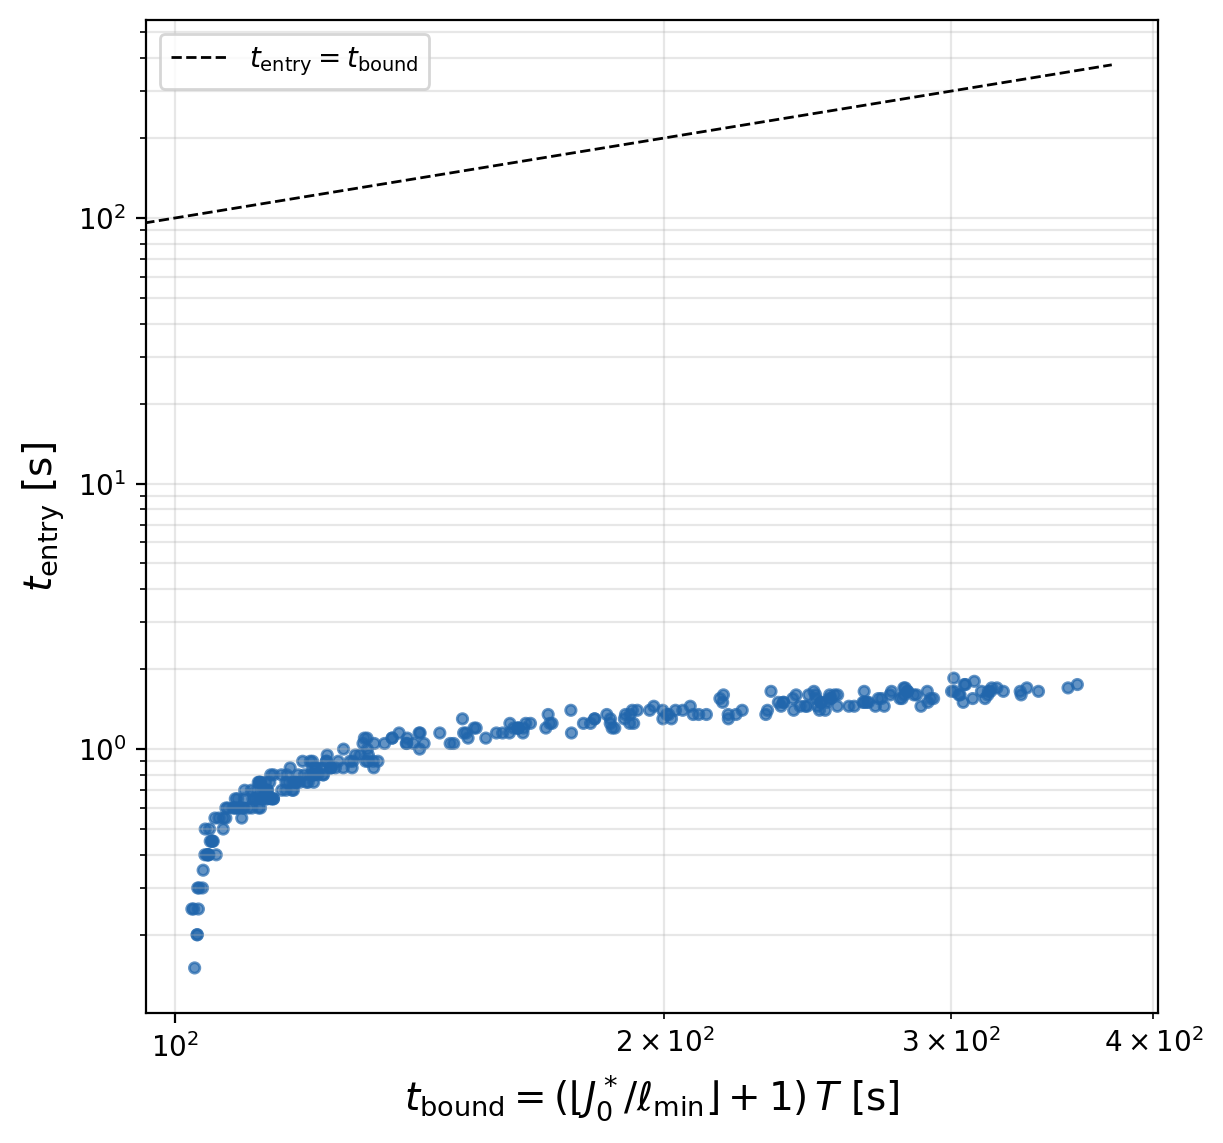

reached runs: 284,  bound satisfied: 284/284
t_entry  : min 0.15  median 1.15  max 1.85 s
t_bound  : min 102.35  median 147.97  max 359.10 s
ratio t_entry/t_bound: median 0.006, max 0.009
  not reached idx 43: infeasible steps   0  J-decrease violations   0  final x = [ 1.64  0.5   2.33 -0.19]
  not reached idx 49: infeasible steps   0  J-decrease violations   0  final x = [-1.26 -1.91  2.27 -0.47]
  not reached idx 128: infeasible steps   0  J-decrease violations   0  final x = [-1.97 -0.51  3.94  0.9 ]
  not reached idx 191: timeout    steps 200  J-decrease violations 181  final x = [ 1.41  0.03 -0.05 -0.  ]
  not reached idx 249: infeasible steps   0  J-decrease violations   0  final x = [1.41 0.47 2.34 0.26]
  not reached idx 313: infeasible steps   0  J-decrease violations   0  final x = [ 1.85  1.27  3.57 -0.98]
  not reached idx 351: infeasible steps   0  J-decrease violations   0  final x = [ 1.43  0.31  4.01 -0.15]
  not reached idx 396: infeasible steps   0  J-decrease violat

In [12]:
# ── Corollary 1: entry time versus t_bound = (floor(J0/ell)+1) T ─────────────
t_entry = np.array([LOGS[i]["check"]["t_entry"] for i in reached])
t_bound = np.array([LOGS[i]["check"]["t_bound"] for i in reached])
ok = t_entry <= t_bound + 1e-9

fig, ax = plt.subplots(figsize=(600 * px_fig, 560 * px_fig), layout="constrained")
fig.set_dpi(200)
ax.scatter(t_bound, t_entry, s=14, c=np.where(ok, "#2166ac", "#d73027"), alpha=0.7)
lim = [0, max(t_bound.max(), t_entry.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label=r"$t_{\rm entry} = t_{\rm bound}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$t_{\rm bound} = (\lfloor J^*_0/\ell_{\min}\rfloor+1)\,T$ [s]", fontsize=14)
ax.set_ylabel(r"$t_{\rm entry}$ [s]", fontsize=14); ax.grid(True, which="both", alpha=0.3); ax.legend()
fig.savefig(os.path.join(ROOT, "figures", "tac_dubins_entry_bound.png"), dpi=200)
plt.show()

print(f"reached runs: {len(reached)},  bound satisfied: {ok.sum()}/{len(reached)}")
print(f"t_entry  : min {t_entry.min():.2f}  median {np.median(t_entry):.2f}  max {t_entry.max():.2f} s")
print(f"t_bound  : min {t_bound.min():.2f}  median {np.median(t_bound):.2f}  max {t_bound.max():.2f} s")
print(f"ratio t_entry/t_bound: median {np.median(t_entry/t_bound):.3f}, max {np.max(t_entry/t_bound):.3f}")
not_reached = [i for i in candidate_idx if LOGS[i]["status"] != "reached"]
for i in not_reached:
    L = LOGS[i]; c = L["check"]
    print(f"  not reached idx {i}: {L['status']:10s} steps {c['n_steps']:3d}  J-decrease violations "
          f"{c['n_decrease_viol']:3d}  final x = {np.round(L['x'][-1], 2)}")